# M08-4 | Is It Really Faster: eager, Q/DQ Graph, fp32 `.pte`, int8 `.pte`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m08_xnnpack_executorch/04_latency.ipynb)

M07 has no int8 kernel, so it does not measure speed; XNNPACK does. With the same model, compare four ways of running:

| Way of running | Where it comes from | What runs |
|---|---|---|
| eager fp32 | the original model | PyTorch eager, every op goes through Python and the dispatcher |
| Q/DQ graph | the result of `convert_pt2e` | PyTorch eager: fp32 computation, plus q/dq |
| fp32 `.pte` | the original model lowered directly without quantizing | ExecuTorch + XNNPACK fp32 kernels |
| int8 `.pte` | the Q/DQ graph lowered again (M08-2) | ExecuTorch + XNNPACK int8 kernels |

Predict first: will the Q/DQ graph be faster than eager? Which one should the int8 `.pte`'s speedup be compared against?

- **A.** TinyConvNet at two widths, latency at batch 1.
- **B.** Split the gain into two parts: switching runtime, then quantizing.

**The numbers depend heavily on the machine** (CPU, thread count, XNNPACK version); look only at the relative relationships. The outputs stored below come from the environment printed at the start, and the commentary is generated from the measurements. This notebook needs executorch (`uv sync --group executorch`).

In [1]:
#| include: false
# On Google Colab: download this tutorial's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "executorch==1.5.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this tutorial's common/
    os.chdir(f"{repo}/en/m08_xnnpack_executorch")

In [2]:
import timeit

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.pt2e import quiet  # must be imported before executorch
from common.env import env_summary
from common.executorch_utils import PteRunner, lower_to_xnnpack, xnnpack_ptq
from common.models import TinyConvNet, example_inputs
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
print(env_summary())

Linux x86_64 | torch 2.14.0+cu130 | threads=1 | mkldnn=True | nnpack=True


## A. Latency at Batch 1

`width` is the channel count of TinyConvNet's middle conv layers (`head_conv` is 2×width). The two widths have the same input size and batch; they differ only in the computation per layer.

Timing method: each variant is warmed up 20 times, then run for 7 rounds of 100 calls each, and the average of the fastest round is taken (least disturbed by background processes). Latency does not depend on the weight values, so an untrained model and a small amount of calibration are enough.

In [3]:
@torch.no_grad()
def latency_us(fn, x, warmup=20, number=100, repeat=7):
    for _ in range(warmup):
        fn(x)
    return min(timeit.repeat(lambda: fn(x), number=number, repeat=repeat)) / number * 1e6


def measure(width):
    """Return (parameter count, {way of running: microseconds})."""
    torch.manual_seed(0)
    model = TinyConvNet(width=width).eval()
    x = example_inputs(1)
    qdq = xnnpack_ptq(model, x, n_calib=32)
    runners = {
        "eager fp32": model,
        "Q/DQ graph": qdq,
        "fp32 .pte": PteRunner(lower_to_xnnpack(model, x)[1]),
        "int8 .pte": PteRunner(lower_to_xnnpack(qdq, x)[1]),
    }
    n_params = sum(p.numel() for p in model.parameters())
    return n_params, {name: latency_us(fn, x[0]) for name, fn in runners.items()}


WIDTHS = [16, 64]
results = {w: measure(w) for w in WIDTHS}
METHODS = list(results[WIDTHS[0]][1])
table([[f"width={w} ({n} parameters)"] + [f"{t[m]:.1f}" for m in METHODS] for w, (n, t) in results.items()],
      ["microseconds (lower is faster)"] + METHODS)

microseconds (lower is faster),eager fp32,Q/DQ graph,fp32 .pte,int8 .pte
width=16 (9940 parameters),166.2,725.2,57.4,59.0
width=64 (150340 parameters),432.1,1333.9,88.0,63.0


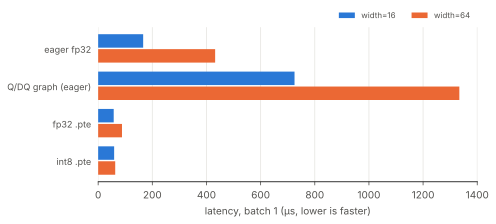

In [4]:
#| code-fold: true
#| code-summary: Plotting code
LABELS = {"eager fp32": "eager fp32", "Q/DQ graph": "Q/DQ graph (eager)", "fp32 .pte": "fp32 .pte", "int8 .pte": "int8 .pte"}
COLORS = {16: "#2a78d6", 64: "#eb6834"}
MUTED, GRID = "#52514e", "#e6e5e1"
fig, ax = plt.subplots(figsize=(6.8, 2.8))
h = 0.36
for j, w in enumerate(WIDTHS):
    t = results[w][1]
    ys = [i + (j - 0.5) * (h + 0.04) for i in range(len(METHODS))]
    ax.barh(ys, [t[m] for m in METHODS], height=h, color=COLORS[w], label=f"width={w}")
ax.set_yticks(range(len(METHODS)), [LABELS[m] for m in METHODS], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("latency, batch 1 (µs, lower is faster)", color=MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED, left=False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=2, frameon=False, labelcolor=MUTED, fontsize=8)
plt.show()

## B. The Gain Splits into Two Parts: Switching Runtime, Then Quantizing

```text
eager fp32 ──switch runtime──→ fp32 .pte ──quantize──→ int8 .pte
```

Work out the factor for each part, with the Q/DQ graph against eager as a reference:

In [5]:
def speedup(before_us, after_us):
    """Going from before to after: print "N× faster" if after is faster, "N× slower" if slower."""
    ratio = before_us / after_us
    return f"{ratio:.2f}× faster" if ratio >= 1 else f"{1 / ratio:.2f}× slower"


table([[f"width={w}", speedup(t["eager fp32"], t["fp32 .pte"]), speedup(t["fp32 .pte"], t["int8 .pte"]),
        speedup(t["eager fp32"], t["Q/DQ graph"])] for w, (_, t) in results.items()],
      ["", "switch runtime (eager → fp32 .pte)", "quantize (fp32 .pte → int8 .pte)", "reference (eager → Q/DQ graph)"])

,switch runtime (eager → fp32 .pte),quantize (fp32 .pte → int8 .pte),reference (eager → Q/DQ graph)
width=16,2.90× faster,1.03× slower,4.36× slower
width=64,4.91× faster,1.40× faster,3.09× slower


In [6]:
small, large = (results[w][1] for w in WIDTHS)
n_small, n_large = (results[w][0] for w in WIDTHS)
if all(t["Q/DQ graph"] > t["eager fp32"] for _, t in results.values()):
    print("* The Q/DQ graph is slower than eager: it is still fp32 computation, just with extra q/dq.")
if all(t["fp32 .pte"] < t["eager fp32"] for _, t in results.values()):
    print("* The unquantized fp32 .pte is already much faster than eager: the whole graph is handed to XNNPACK at once, saving the overhead of every op going through Python and the dispatcher.")
    print(f"  The parameter count grows {n_large / n_small:.0f}×, yet eager is only {large['eager fp32'] / small['eager fp32']:.1f}× slower: "
          "most of eager's time goes to call overhead, not computation (inference).")
gain_small, gain_large = (t["fp32 .pte"] / t["int8 .pte"] for t in (small, large))
if gain_small > 1 and gain_large > gain_small:
    print(f"* int8 speedup over the fp32 .pte: {gain_small:.2f}× at width 16, {gain_large:.2f}× at width 64; the more computation, the more visible.")
    print("  When the model is too small, fixed overhead (the call, fp32 ↔ int8 conversion at input and output) takes a large share (inference; only two widths were measured).")
elif gain_small > 1 or gain_large > 1:
    print(f"* int8 .pte speedup over fp32 .pte: {gain_small:.2f}× / {gain_large:.2f}×, not growing with width.")
else:
    print("* On this machine, the int8 .pte is not faster than the fp32 .pte: whether XNNPACK's int8 kernels are fast depends on the CPU's instruction set.")

* The Q/DQ graph is slower than eager: it is still fp32 computation, just with extra q/dq.
* The unquantized fp32 .pte is already much faster than eager: the whole graph is handed to XNNPACK at once, saving the overhead of every op going through Python and the dispatcher.
  The parameter count grows 15×, yet eager is only 2.6× slower: most of eager's time goes to call overhead, not computation (inference).
* int8 .pte speedup over fp32 .pte: 0.97× / 1.40×, not growing with width.


"Faster after deployment" has to be looked at in two parts: the gain from switching runtime and the gain from quantizing are two separate things. So when comparing int8, the baseline is **the fp32 on the same runtime** (the fp32 `.pte`), not PyTorch eager (M07 overview, "The Baseline for Speed").

## Summary

- Quantization by itself does not make things faster; the Q/DQ graph is actually slower in eager. A backend has to swap it for int8 kernels.
- Switching to ExecuTorch + XNNPACK already makes fp32 much faster; the gain from int8 must be measured against the fp32 `.pte`.
- The model here is tiny, and part of what is measured is call overhead; measure the real gain with your own model on the target device.